## Model 2: Memory Reinforcement

The baseline model assumes that a memory passively decays over time. However, memories can be strengthened through review or retrieval.

To model reinforcement, a review at time t increases the synaptic weight according to:

w_new = w + ⍺(1 - w)

where ⍺ is the learning rate. The term (1 - w) represents the remaining capacity for the memory to strengthen, preventing the weight from exceeding 1.

Between reviews, the memory continues to decay exponentially.

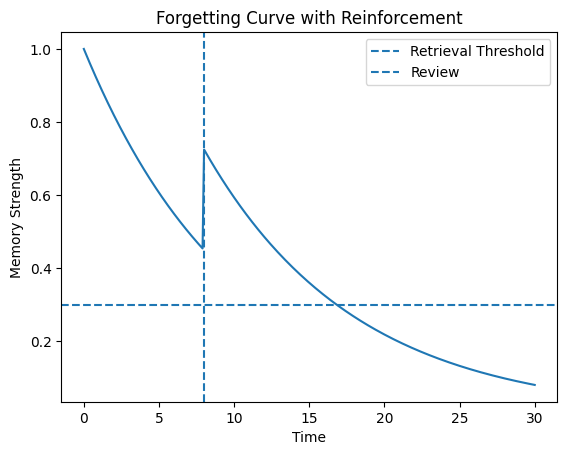

In [1]:
import numpy as np
import matplotlib.pyplot as plt

decay_rate = 0.1
retrieval_threshold = 0.3

review_time = 8
learning_rate = 0.5

time = np.linspace(0, 30, 301)
dt = time[1]-time[0]

memory_strength = np.zeros(len(time))
memory_strength[0] = 1.0  # Initial memory strength

for i in range(1, len(time)):
    memory_strength[i] = memory_strength[i-1] * np.exp(-decay_rate * dt)

    if time[i-1] < review_time <= time[i]:
        memory_strength[i] = memory_strength[i] + learning_rate * (1 - memory_strength[i])

plt.plot(time, memory_strength)
plt.axhline(y=retrieval_threshold, linestyle='--', label='Retrieval Threshold')
plt.axvline(x=review_time, linestyle='--', label='Review')

plt.xlabel('Time')
plt.ylabel('Memory Strength')
plt.title('Forgetting Curve with Reinforcement')
plt.legend()

plt.show()

